# Project 9: Hospital Appointment Operations Analysis
**Industry:** Healthcare Operations  
**Dataset:** `09_hospital_appointments_100_records.csv`  
**Purpose:** Analyze appointment attendance, waiting times, department workload and estimated consultation fees.

> This is a synthetic operational dataset. It contains no clinical diagnoses or treatment information. Findings describe this sample only and must not be interpreted as medical conclusions.

## 1. Business problem
Hospital administrators need to understand appointment attendance, waiting-time patterns and department workload. This analysis identifies operational patterns that may help improve scheduling and patient communication.

## 2. Objectives
- Inspect and clean appointment records.
- Measure attendance and no-show rates.
- Compare department waiting times and workload.
- Examine SMS reminders and appointment type.
- Use NumPy for descriptive statistics and IQR-based outlier detection.
- Estimate consultation-fee totals for attended appointments.
- Provide evidence-based operational recommendations.

## 3. Data-cleaning decisions
- Duplicate `Appointment_ID` values are reported. For appointment-level analysis, only the first occurrence of each ID is retained.
- Missing waiting times for no-shows/cancellations are structurally not applicable and are left missing.
- Missing waiting times for attended appointments are imputed using the median waiting time of the same department. A flag preserves which values were imputed.
- Outlier detection uses attended appointment waiting times after the above cleaning step.

## 4. Tools
Python, Pandas, NumPy, Matplotlib and Seaborn.


In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

# Read the CSV file. This path works when the notebook is run from the project root.
DATA_PATH = Path("data/09_hospital_appointments_100_records.csv")
if not DATA_PATH.exists():
    # Also allow running the notebook from the src folder.
    DATA_PATH = Path("../data/09_hospital_appointments_100_records.csv")

appointments = pd.read_csv(DATA_PATH)
appointments["Appointment_Date"] = pd.to_datetime(appointments["Appointment_Date"])

print("Dataset loaded successfully.")
print("Shape:", appointments.shape)


Dataset loaded successfully.
Shape: (100, 9)


## Task 1 — Load and inspect appointment records

In [2]:
display(appointments.head())
print("\nDataset information:")
appointments.info()
print("\nDescriptive statistics:")
display(appointments.describe(include="all").T)
print("\nColumn names:", appointments.columns.tolist())


,Appointment_ID,Patient_ID,Appointment_Date,Department,Appointment_Type,Attendance_Status,Waiting_Time_Minutes,SMS_Reminder,Consultation_Fee
0,APT1001,PAT0042,2026-09-05,Orthopedics,Follow-up,Attended,34.0,No,788
1,APT1002,PAT0049,2026-10-05,Cardiology,Follow-up,Attended,32.0,No,892
2,APT1003,PAT0031,2026-09-30,Neurology,New,Attended,17.0,Yes,1022
3,APT1004,PAT0051,2026-09-20,Neurology,Follow-up,Attended,48.0,Yes,959
4,APT1005,PAT0060,2026-09-20,Neurology,New,Attended,31.0,Yes,1071



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Appointment_ID        100 non-null    object        
 1   Patient_ID            100 non-null    object        
 2   Appointment_Date      100 non-null    datetime64[ns]
 3   Department            100 non-null    object        
 4   Appointment_Type      100 non-null    object        
 5   Attendance_Status     100 non-null    object        
 6   Waiting_Time_Minutes  58 non-null     float64       
 7   SMS_Reminder          100 non-null    object        
 8   Consultation_Fee      100 non-null    int64         
dtypes: datetime64[ns](1), float64(1), int64(1), object(6)
memory usage: 7.2+ KB

Descriptive statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Appointment_ID,100,99,APT1099,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Patient_ID,100,60,PAT0064,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Appointment_Date,100,NaN,NaN,NaN,2026-09-24 05:02:24,2026-09-02 00:00:00,2026-09-15 00:00:00,2026-09-24 00:00:00,2026-10-05 00:00:00,2026-10-14 00:00:00,NaN
Department,100,6,Dermatology,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Appointment_Type,100,2,Follow-up,58,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attendance_Status,100,3,Attended,62,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Waiting_Time_Minutes,58.0,NaN,NaN,NaN,28.741379,2.0,22.0,27.0,34.0,62.0,11.859648
SMS_Reminder,100,2,Yes,63,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Consultation_Fee,100.0,NaN,NaN,NaN,748.14,327.0,579.75,714.0,922.0,1125.0,207.150266



Column names: ['Appointment_ID', 'Patient_ID', 'Appointment_Date', 'Department', 'Appointment_Type', 'Attendance_Status', 'Waiting_Time_Minutes', 'SMS_Reminder', 'Consultation_Fee']


## Task 2 — Identify and handle missing waiting times

In [3]:
print("Missing values by column:")
display(appointments.isna().sum().to_frame("Missing_Count"))

# Preserve a flag before imputing attended appointment values.
appointments["Waiting_Time_Imputed"] = False
attended_missing = (
    appointments["Attendance_Status"].eq("Attended")
    & appointments["Waiting_Time_Minutes"].isna()
)
appointments.loc[attended_missing, "Waiting_Time_Imputed"] = True

# Missing waiting times for non-attended appointments are not applicable.
not_attended_missing = (
    appointments["Attendance_Status"].ne("Attended")
    & appointments["Waiting_Time_Minutes"].isna()
)
print("Missing waiting times for attended appointments:", int(attended_missing.sum()))
print("Missing waiting times for non-attended appointments (left as N/A):", int(not_attended_missing.sum()))

# Impute only attended records, using their department median.
department_medians = appointments.loc[
    appointments["Attendance_Status"].eq("Attended")
].groupby("Department")["Waiting_Time_Minutes"].median()

for department, median_value in department_medians.items():
    mask = (
        appointments["Department"].eq(department)
        & appointments["Attendance_Status"].eq("Attended")
        & appointments["Waiting_Time_Minutes"].isna()
    )
    appointments.loc[mask, "Waiting_Time_Minutes"] = median_value

print("\nMissing values after handling:")
display(appointments.isna().sum().to_frame("Remaining_Missing"))


Missing values by column:


,Missing_Count
Appointment_ID,0
Patient_ID,0
Appointment_Date,0
Department,0
Appointment_Type,0
Attendance_Status,0
Waiting_Time_Minutes,42
SMS_Reminder,0
Consultation_Fee,0


Missing waiting times for attended appointments: 4
Missing waiting times for non-attended appointments (left as N/A): 38

Missing values after handling:


,Remaining_Missing
Appointment_ID,0
Patient_ID,0
Appointment_Date,0
Department,0
Appointment_Type,0
Attendance_Status,0
Waiting_Time_Minutes,38
SMS_Reminder,0
Consultation_Fee,0
Waiting_Time_Imputed,0


## Task 3 — Check duplicate Appointment_ID values

In [4]:
duplicate_mask = appointments["Appointment_ID"].duplicated(keep="first")
duplicate_records = appointments.loc[duplicate_mask]
print("Duplicate Appointment_ID rows:", int(duplicate_mask.sum()))
display(duplicate_records)

# Retain the first occurrence of each appointment ID for all subsequent appointment-level analysis.
appointments = appointments.drop_duplicates(subset="Appointment_ID", keep="first").copy()
print("Records after duplicate removal:", len(appointments))
print("Remaining duplicate IDs:", int(appointments["Appointment_ID"].duplicated().sum()))


Duplicate Appointment_ID rows: 1


,Appointment_ID,Patient_ID,Appointment_Date,Department,Appointment_Type,Attendance_Status,Waiting_Time_Minutes,SMS_Reminder,Consultation_Fee,Waiting_Time_Imputed
99,APT1099,PAT0074,2026-09-07,Cardiology,Follow-up,Attended,30.0,Yes,953,False


Records after duplicate removal: 99
Remaining duplicate IDs: 0


## Task 4 — Total appointments and attendance-status percentages

In [5]:
total_appointments = len(appointments)
attendance_counts = appointments["Attendance_Status"].value_counts()
attendance_percentages = (
    appointments["Attendance_Status"].value_counts(normalize=True).mul(100).round(2)
)
attendance_summary = pd.DataFrame({
    "Appointment_Count": attendance_counts,
    "Percentage": attendance_percentages
})
print("Total appointments:", total_appointments)
display(attendance_summary)


Total appointments: 99


,Appointment_Count,Percentage
Attendance_Status,,
Attended,61,61.62
No-show,27,27.27
Cancelled,11,11.11


## Task 5 — Average waiting time by department

In [6]:
attended = appointments.loc[appointments["Attendance_Status"].eq("Attended")].copy()
department_waiting_summary = (
    attended.groupby("Department")
    .agg(
        Attended_Appointments=("Appointment_ID", "count"),
        Average_Wait_Minutes=("Waiting_Time_Minutes", "mean"),
        Median_Wait_Minutes=("Waiting_Time_Minutes", "median"),
        Maximum_Wait_Minutes=("Waiting_Time_Minutes", "max")
    )
    .round(2)
    .sort_values("Average_Wait_Minutes", ascending=False)
)
display(department_waiting_summary)


,Attended_Appointments,Average_Wait_Minutes,Median_Wait_Minutes,Maximum_Wait_Minutes
Department,,,,
Neurology,11,36.73,36.0,59.0
Orthopedics,11,33.64,32.0,51.0
Cardiology,13,30.77,30.0,62.0
General Medicine,6,25.17,24.5,38.0
ENT,8,23.25,25.0,34.0
Dermatology,12,19.67,20.5,40.0


## Task 6 — Departments with the highest no-show percentage

In [7]:
department_attendance = pd.crosstab(
    appointments["Department"],
    appointments["Attendance_Status"]
)
department_attendance["Total_Appointments"] = department_attendance.sum(axis=1)
department_attendance["No_Show_Percentage"] = (
    department_attendance.get("No-show", 0) / department_attendance["Total_Appointments"] * 100
)
department_attendance = department_attendance.sort_values(
    "No_Show_Percentage", ascending=False
).round(2)
display(department_attendance)
print("\nDepartment with highest no-show percentage:",
      department_attendance["No_Show_Percentage"].idxmax())


Attendance_Status,Attended,Cancelled,No-show,Total_Appointments,No_Show_Percentage
Department,,,,,
ENT,8,1,7,16,43.75
Dermatology,12,2,7,21,33.33
General Medicine,6,1,3,10,30.00
Orthopedics,11,3,4,18,22.22
Cardiology,13,1,3,17,17.65
Neurology,11,3,3,17,17.65



Department with highest no-show percentage: ENT


## Task 7 — Compare no-show rates for SMS reminder Yes and No

In [8]:
sms_attendance_counts = pd.crosstab(
    appointments["SMS_Reminder"], appointments["Attendance_Status"]
)
sms_attendance_percentages = pd.crosstab(
    appointments["SMS_Reminder"],
    appointments["Attendance_Status"],
    normalize="index"
).mul(100).round(2)
print("Counts:")
display(sms_attendance_counts)
print("Row percentages:")
display(sms_attendance_percentages)

no_show_rates = (
    appointments.assign(Is_No_Show=appointments["Attendance_Status"].eq("No-show"))
    .groupby("SMS_Reminder")["Is_No_Show"].mean().mul(100).round(2)
)
print("No-show percentage by SMS reminder:")
display(no_show_rates.to_frame("No_Show_Percentage"))


Counts:


Attendance_Status,Attended,Cancelled,No-show
SMS_Reminder,,,
No,19,4,14
Yes,42,7,13


Row percentages:


Attendance_Status,Attended,Cancelled,No-show
SMS_Reminder,,,
No,51.35,10.81,37.84
Yes,67.74,11.29,20.97


No-show percentage by SMS reminder:


,No_Show_Percentage
SMS_Reminder,
No,37.84
Yes,20.97


## Task 8 — Average consultation fee by department

In [9]:
department_fee_summary = (
    appointments.groupby("Department")
    .agg(
        Appointment_Count=("Appointment_ID", "count"),
        Average_Consultation_Fee=("Consultation_Fee", "mean"),
        Median_Consultation_Fee=("Consultation_Fee", "median")
    )
    .round(2)
    .sort_values("Average_Consultation_Fee", ascending=False)
)
display(department_fee_summary)


,Appointment_Count,Average_Consultation_Fee,Median_Consultation_Fee
Department,,,
Neurology,17,1039.41,1036.0
Cardiology,17,913.82,892.0
Orthopedics,18,794.39,811.0
Dermatology,21,617.10,619.0
ENT,16,578.25,572.5
General Medicine,10,414.60,405.5


## Task 9 — Appointment volume by date and department

Department,Cardiology,Dermatology,ENT,General Medicine,Neurology,Orthopedics
Appointment_Date,,,,,,
2026-09-02,0,0,0,0,1,0
2026-09-03,1,0,0,0,0,0
2026-09-04,0,2,0,0,0,1
2026-09-05,1,0,0,2,0,1
2026-09-06,0,1,0,0,0,1
2026-09-07,0,0,0,0,0,1
2026-09-08,1,0,1,0,0,0
2026-09-09,0,0,1,1,1,0
2026-09-10,1,0,0,0,0,0


Total appointment volume represented in date-department table: 99


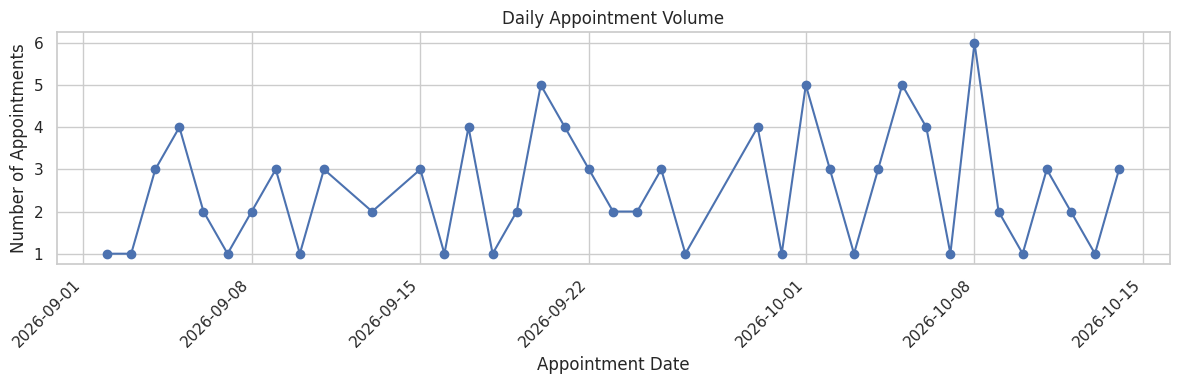

In [10]:
daily_department_volume = pd.pivot_table(
    appointments,
    index="Appointment_Date",
    columns="Department",
    values="Appointment_ID",
    aggfunc="count",
    fill_value=0
).sort_index()
display(daily_department_volume.head(15))
print("Total appointment volume represented in date-department table:",
      int(daily_department_volume.to_numpy().sum()))

daily_total = appointments.groupby("Appointment_Date").size()
plt.figure(figsize=(12, 4))
daily_total.plot(kind="line", marker="o")
plt.title("Daily Appointment Volume")
plt.xlabel("Appointment Date")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Task 10 — Compare waiting times for new and follow-up appointments

,count,mean,median,min,max
Appointment_Type,,,,,
Follow-up,34,26.76,25.5,2.0,59.0
New,27,31.00,30.0,11.0,62.0


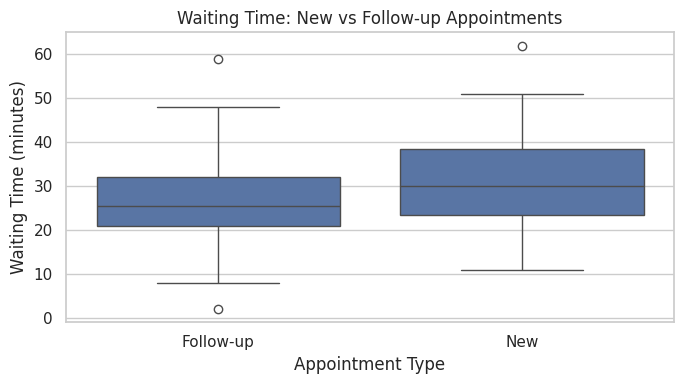

In [11]:
appointment_type_wait = (
    attended.groupby("Appointment_Type")["Waiting_Time_Minutes"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)
display(appointment_type_wait)

plt.figure(figsize=(7, 4))
sns.boxplot(data=attended, x="Appointment_Type", y="Waiting_Time_Minutes")
plt.title("Waiting Time: New vs Follow-up Appointments")
plt.xlabel("Appointment Type")
plt.ylabel("Waiting Time (minutes)")
plt.tight_layout()
plt.show()


## Task 11 — NumPy median, quartiles and standard deviation of waiting time

In [12]:
waiting_array = attended["Waiting_Time_Minutes"].dropna().to_numpy(dtype=float)

waiting_median = np.median(waiting_array)
q1, q2, q3 = np.percentile(waiting_array, [25, 50, 75])
waiting_std_population = np.std(waiting_array, ddof=0)
waiting_std_sample = np.std(waiting_array, ddof=1)

print(f"Number of attended appointments with waiting-time values: {len(waiting_array)}")
print(f"Median: {waiting_median:.2f} minutes")
print(f"Q1 (25th percentile): {q1:.2f} minutes")
print(f"Q2 (50th percentile): {q2:.2f} minutes")
print(f"Q3 (75th percentile): {q3:.2f} minutes")
print(f"Population standard deviation: {waiting_std_population:.2f} minutes")
print(f"Sample standard deviation: {waiting_std_sample:.2f} minutes")


Number of attended appointments with waiting-time values: 61
Median: 26.00 minutes
Q1 (25th percentile): 22.00 minutes
Q2 (50th percentile): 26.00 minutes
Q3 (75th percentile): 34.00 minutes
Population standard deviation: 11.48 minutes
Sample standard deviation: 11.58 minutes


## Task 12 — Identify unusually long waiting times using IQR

In [13]:
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

waiting_outliers = attended.loc[
    (attended["Waiting_Time_Minutes"] < lower_bound)
    | (attended["Waiting_Time_Minutes"] > upper_bound),
    ["Appointment_ID", "Appointment_Date", "Department",
     "Appointment_Type", "Waiting_Time_Minutes"]
].sort_values("Waiting_Time_Minutes", ascending=False)

print(f"IQR: {iqr:.2f}")
print(f"Lower fence: {lower_bound:.2f} minutes")
print(f"Upper fence: {upper_bound:.2f} minutes")
print("Potential waiting-time outliers:", len(waiting_outliers))
display(waiting_outliers)


IQR: 12.00
Lower fence: 4.00 minutes
Upper fence: 52.00 minutes
Potential waiting-time outliers: 3


,Appointment_ID,Appointment_Date,Department,Appointment_Type,Waiting_Time_Minutes
74,APT1075,2026-10-01,Cardiology,New,62.0
30,APT1031,2026-09-21,Neurology,Follow-up,59.0
21,APT1022,2026-09-17,Dermatology,Follow-up,2.0


## Task 13 — Create waiting-time categories

,Appointment_Count,Percentage
Waiting_Time_Category,,
0-15 minutes,7,11.48
16-30 minutes,30,49.18
31-60 minutes,23,37.70
Above 60 minutes,1,1.64


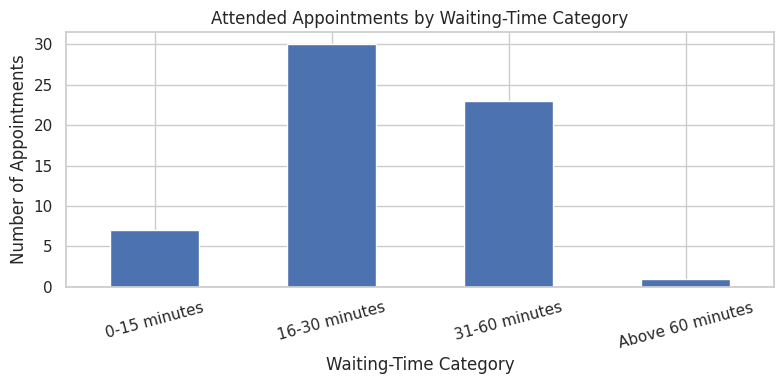

In [14]:
# Categories are operational bands chosen for this teaching analysis.
# They are not medical or regulatory thresholds.
bins = [-np.inf, 15, 30, 60, np.inf]
labels = ["0-15 minutes", "16-30 minutes", "31-60 minutes", "Above 60 minutes"]

attended["Waiting_Time_Category"] = pd.cut(
    attended["Waiting_Time_Minutes"],
    bins=bins,
    labels=labels,
    right=True
)
waiting_band_summary = (
    attended["Waiting_Time_Category"]
    .value_counts(sort=False)
    .rename_axis("Waiting_Time_Category")
    .to_frame("Appointment_Count")
)
waiting_band_summary["Percentage"] = (
    waiting_band_summary["Appointment_Count"] / waiting_band_summary["Appointment_Count"].sum() * 100
).round(2)
display(waiting_band_summary)

plt.figure(figsize=(8, 4))
waiting_band_summary["Appointment_Count"].plot(kind="bar")
plt.title("Attended Appointments by Waiting-Time Category")
plt.xlabel("Waiting-Time Category")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## Task 14 — Estimated total consultation fees for attended appointments

In [15]:
attended_fee_summary = (
    attended.groupby("Department")
    .agg(
        Attended_Appointments=("Appointment_ID", "count"),
        Estimated_Attended_Fees=("Consultation_Fee", "sum"),
        Average_Fee=("Consultation_Fee", "mean")
    )
    .sort_values("Estimated_Attended_Fees", ascending=False)
)
display(attended_fee_summary)
estimated_total_attended_fees = attended["Consultation_Fee"].sum()
print(f"Estimated total consultation fees for attended appointments: ₹{estimated_total_attended_fees:,.2f}")
print("Assumption: each attended appointment's listed consultation fee is treated as collected/earned.")


,Attended_Appointments,Estimated_Attended_Fees,Average_Fee
Department,,,
Cardiology,13,11874,913.384615
Neurology,11,11391,1035.545455
Orthopedics,11,8668,788.000000
Dermatology,12,7520,626.666667
ENT,8,4520,565.000000
General Medicine,6,2483,413.833333


Estimated total consultation fees for attended appointments: ₹46,456.00
Assumption: each attended appointment's listed consultation fee is treated as collected/earned.


## Task 15 — Five operational recommendations

In [16]:
# Recommendations are generated from the observed sample metrics.
highest_noshow_dept = department_attendance["No_Show_Percentage"].idxmax()
highest_noshow_rate = department_attendance.loc[highest_noshow_dept, "No_Show_Percentage"]

sms_rates = no_show_rates.to_dict()
if "Yes" in sms_rates and "No" in sms_rates:
    sms_direction = (
        "The observed no-show rate is lower for appointments with SMS reminders."
        if sms_rates["Yes"] < sms_rates["No"]
        else "The observed no-show rate is not lower for appointments with SMS reminders."
    )
else:
    sms_direction = "The sample does not contain both SMS reminder groups."

busiest_date = daily_total.idxmax()
busiest_count = int(daily_total.max())
long_wait_dept = department_waiting_summary["Average_Wait_Minutes"].idxmax()
long_wait_avg = department_waiting_summary.loc[long_wait_dept, "Average_Wait_Minutes"]
outlier_count = len(waiting_outliers)

recommendations = [
    f"Review appointment confirmation and rescheduling processes in {highest_noshow_dept}, which has the highest observed no-show percentage ({highest_noshow_rate:.1f}%).",
    f"Evaluate the SMS reminder workflow. {sms_direction} In this dataset, the no-show rates are {sms_rates.get('Yes', np.nan):.1f}% for Yes and {sms_rates.get('No', np.nan):.1f}% for No; this is an association, not proof that reminders cause the difference.",
    f"Review staffing and appointment-slot allocation around {busiest_date.date()}, the busiest date in the sample ({busiest_count} appointments).",
    f"Audit scheduling and queue processes in {long_wait_dept}, which has the highest department average waiting time ({long_wait_avg:.1f} minutes). Consider appointment spacing and workload balancing.",
    f"Review the {outlier_count} potential unusually long waiting-time records individually and monitor waiting-time bands regularly; IQR flags unusual values but does not establish the reason for a delay."
]

for number, recommendation in enumerate(recommendations, start=1):
    print(f"{number}. {recommendation}")


1. Review appointment confirmation and rescheduling processes in ENT, which has the highest observed no-show percentage (43.8%).
2. Evaluate the SMS reminder workflow. The observed no-show rate is lower for appointments with SMS reminders. In this dataset, the no-show rates are 21.0% for Yes and 37.8% for No; this is an association, not proof that reminders cause the difference.
3. Review staffing and appointment-slot allocation around 2026-10-08, the busiest date in the sample (6 appointments).
4. Audit scheduling and queue processes in Neurology, which has the highest department average waiting time (36.7 minutes). Consider appointment spacing and workload balancing.
5. Review the 3 potential unusually long waiting-time records individually and monitor waiting-time bands regularly; IQR flags unusual values but does not establish the reason for a delay.


## Conclusion and limitations
This notebook evaluates appointment operations using the supplied synthetic sample. It summarizes attendance, waiting times, department workload and estimated fees. The analysis is descriptive: it cannot establish that SMS reminders cause attendance changes, and it does not explain why a particular delay or no-show occurred.

**Limitations and assumptions**
1. The dataset contains only 100 synthetic records and may not represent real hospital operations.
2. Missing waiting times for non-attended appointments are treated as not applicable.
3. Missing waiting times for attended appointments are imputed using the department median; this can affect averages and variability.
4. One duplicate appointment ID is excluded after being reported, to avoid double-counting.
5. Consultation-fee totals are estimates based on listed fees for attended appointments; actual payment, discounts or refunds are not provided.
6. Waiting-time categories are descriptive bands selected for this project, not official service standards.

## Reproducibility
Install dependencies with:
```bash
pip install pandas numpy matplotlib seaborn jupyter
```
Run:
```bash
jupyter notebook
```
Open this notebook from the project root so the relative dataset path resolves.
